# Notebook 02 — Exploratory Data Analysis (EDA)

**Enterprise Credit Risk Modeling & Validation Framework**

**Input:** `data/interim/clean_data.parquet`

**Objective:** Understand the distribution of features, identify patterns related to credit risk, and derive business insights that will guide feature engineering and modelling.

**Sections:**
1. Target Analysis — Default Rate & Class Imbalance
2. Numerical Feature Distributions
3. Categorical Feature Distributions
4. Outlier Analysis
5. Correlation Analysis
6. Default Rate by Key Variables
7. Time Trend Analysis
8. Business Insights Summary

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

from src.utils import setup_logging, set_plot_style, save_figure, PLOT_COLOR, ACCENT_COLOR

setup_logging()
set_plot_style()

INTERIM_PATH = 'data/interim/clean_data.parquet'

df = pd.read_parquet(INTERIM_PATH)
print(f'Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head(3)

Loaded: 2,260,638 rows x 96 columns


,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,total_pymnt,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,collections_12_mths_ex_med,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,hardship_flag,disbursement_method,debt_settlement_flag,mths_since_earliest_cr_line,default,recovery_rate,credit_conversion_factor
0,6000,6000,36,10.5900,195.2800,C,C2,0,RENT,20000.0000,Not Verified,2007-06-01,Does not meet the credit policy. Status:Fully ...,debt_consolidation,CT,12.9000,0,695.0000,699.0000,4,45.0000,5,0,13660.0000,66.0000,6,f,0.0000,7029.8711,6000.0000,1029.8700,0.0000,0.0000,0.0000,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,Cash,N,137,1,0.0000,0.0000
1,4400,4400,36,9.6400,141.2500,B,B4,2,MORTGAGE,30000.0000,Not Verified,2007-06-01,Does not meet the credit policy. Status:Fully ...,debt_consolidation,NJ,3.7200,0,695.0000,699.0000,0,0.0000,4,0,3493.0000,63.5000,5,f,0.0000,5084.7251,4400.0000,684.7200,0.0000,0.0000,0.0000,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,Cash,N,35,1,0.0000,0.0000
2,7500,7500,36,13.7500,255.4300,E,E2,0,OWN,22000.0000,Not Verified,2007-06-01,Fully Paid,debt_consolidation,MA,14.2900,1,660.0000,664.0000,0,11.0000,7,0,4175.0000,51.5000,8,f,0.0000,9195.2637,7500.0000,1695.2600,0.0000,0.0000,0.0000,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,Cash,N,44,1,0.0000,0.0000


## 1. Target Analysis — Default Rate & Class Imbalance

Understanding the target distribution is the first step in credit risk modeling.
Class imbalance directly affects model training strategy and threshold selection.

In [2]:
good = df['default'].sum()
bad  = (df['default'] == 0).sum()
total = len(df)
default_rate = bad / total

print('=== PD Target Summary ===')
print(f'Total loans     : {total:>10,}')
print(f'Good (default=1): {good:>10,}  ({good/total:.1%})')
print(f'Bad  (default=0): {bad:>10,}  ({bad/total:.1%})')
print(f'Default rate    : {default_rate:.2%}')
print(f'\nClass imbalance ratio (good:bad) = {good/bad:.1f}:1')

=== PD Target Summary ===
Total loans     :  2,260,638
Good (default=1):  1,969,814  (87.1%)
Bad  (default=0):    290,824  (12.9%)
Default rate    : 12.86%

Class imbalance ratio (good:bad) = 6.8:1


## 2. Numerical Feature Distributions

Examining the distribution of key numerical features available at loan origination.
Post-outcome features (recoveries, total_pymnt, etc.) are excluded from this view — they are only used to construct LGD/EAD targets.

In [3]:
# Features available at loan origination (no post-outcome leakage)
num_features = [
    'loan_amnt', 'int_rate', 'annual_inc', 'dti',
    'revol_util', 'mths_since_earliest_cr_line',
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'total_acc',
]

print('Descriptive statistics for key numerical features:')
print(df[num_features].describe().T.to_string())

Descriptive statistics for key numerical features:
                                   count       mean         std      min        25%        50%        75%            max
loan_amnt                   2260638.0000 15047.0654   9190.2064 500.0000  8000.0000 12900.0000 20000.0000     40000.0000
int_rate                    2260638.0000    13.0929      4.8321   5.3100     9.4900    12.6200    15.9900        30.9900
annual_inc                  2260638.0000 77992.4844 112696.6406   0.0000 46000.0000 65000.0000 93000.0000 110000000.0000
dti                         2258927.0000    18.8243     14.1834  -1.0000    11.8900    17.8400    24.4900       999.0000
revol_util                  2258865.0000    50.3377     24.7131   0.0000    31.5000    50.3000    69.4000       892.3000
mths_since_earliest_cr_line 2260638.0000   196.7361     92.1565   6.0000   135.0000   178.0000   243.0000       999.0000
delinq_2yrs                 2260638.0000     0.3069      0.8672   0.0000     0.0000     0.0000     0.0

2026-07-26 00:45:15 | INFO     | src.utils | Figure saved → reports\02_numerical_distributions.png


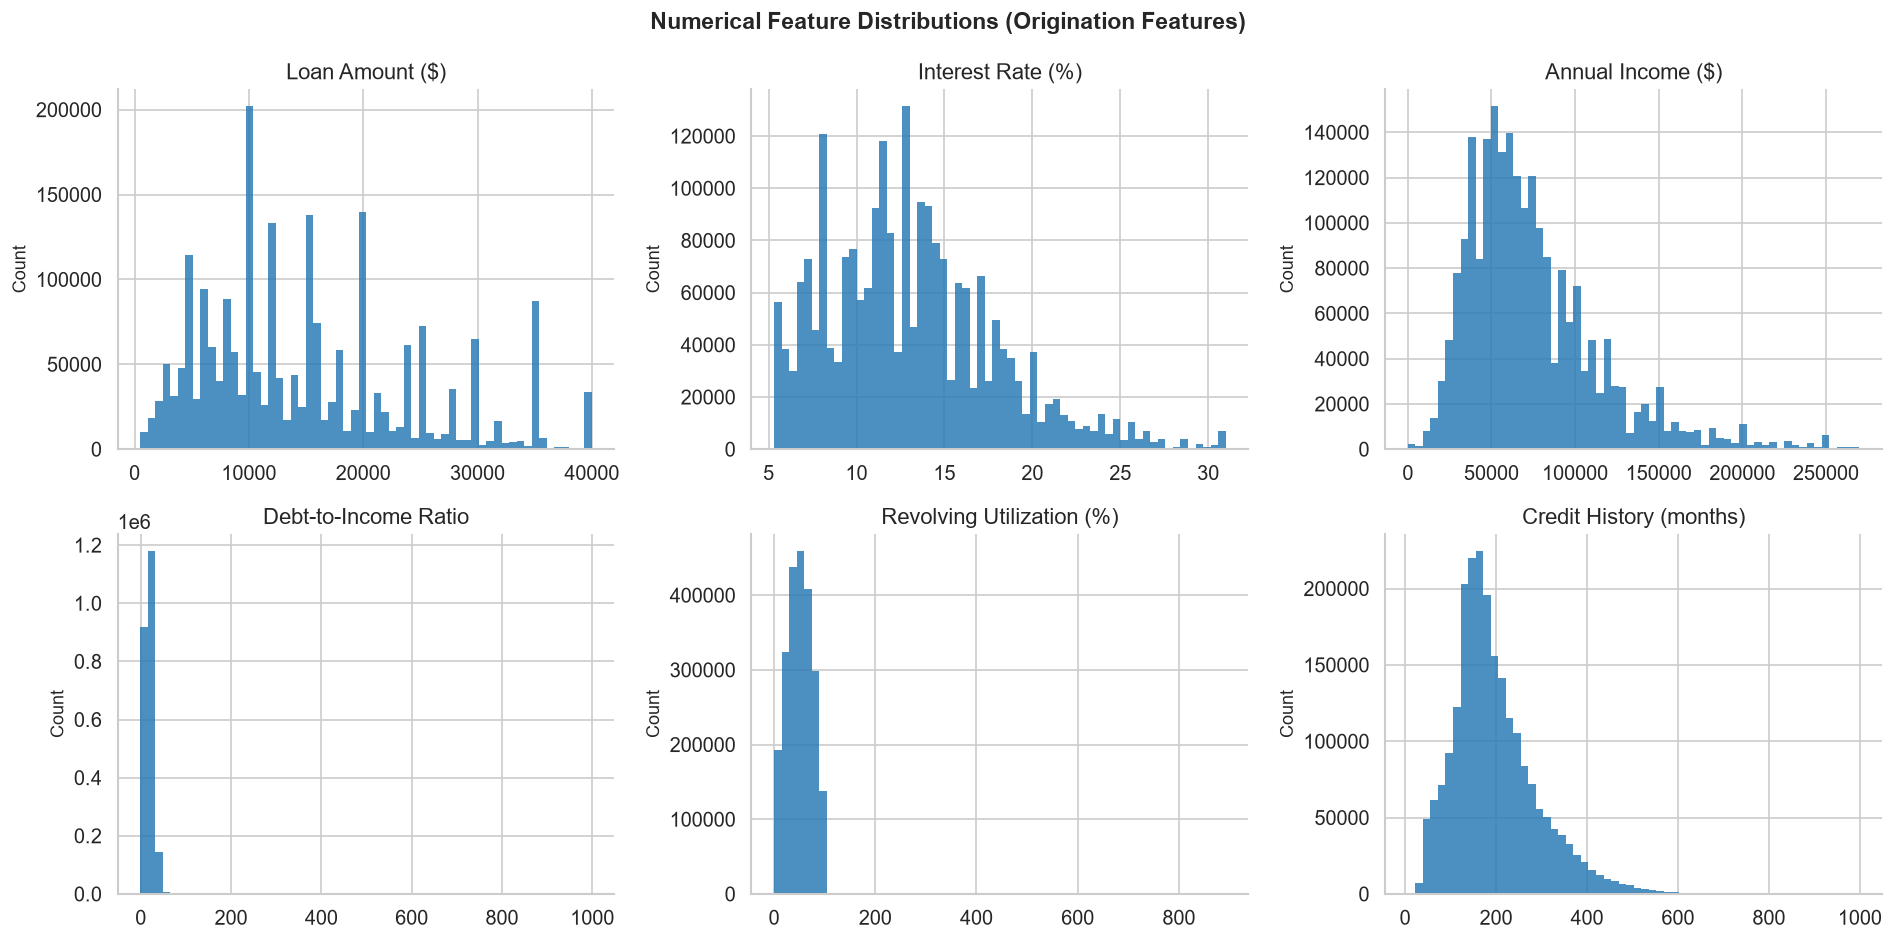

In [4]:
plot_features = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'revol_util', 'mths_since_earliest_cr_line']
plot_titles   = ['Loan Amount ($)', 'Interest Rate (%)', 'Annual Income ($)', 'Debt-to-Income Ratio', 'Revolving Utilization (%)', 'Credit History (months)']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, (feat, title) in enumerate(zip(plot_features, plot_titles)):
    col_data = df[feat].dropna()
    # Cap annual_inc at 99th percentile for readability
    if feat == 'annual_inc':
        cap = col_data.quantile(0.99)
        col_data = col_data[col_data <= cap]
    axes[i].hist(col_data, bins=60, color=PLOT_COLOR, edgecolor='none', alpha=0.85)
    axes[i].set_title(title)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

fig.suptitle('Numerical Feature Distributions (Origination Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
save_figure(fig, '02_numerical_distributions.png')
plt.show()

## 3. Categorical Feature Distributions

2026-07-26 00:45:33 | INFO     | src.utils | Figure saved → reports\02_categorical_distributions.png


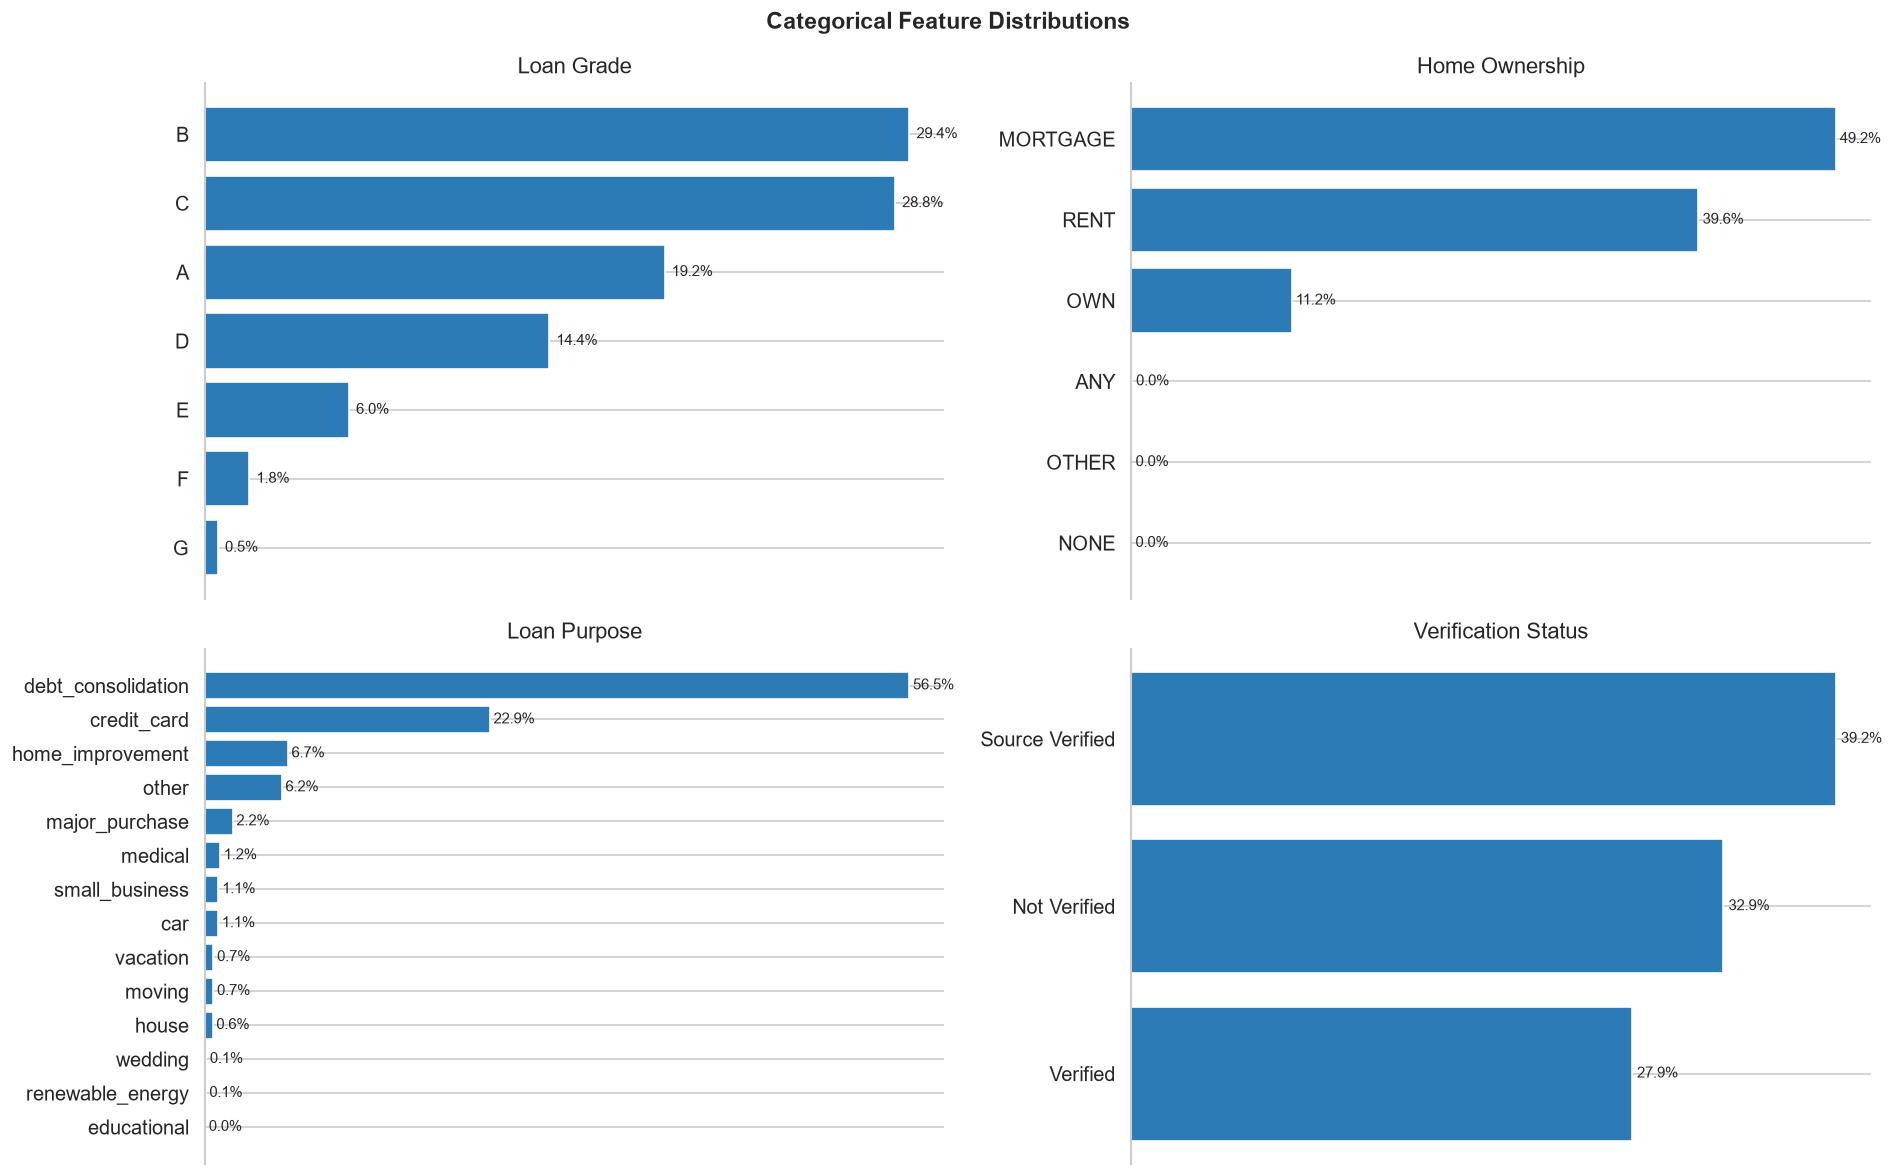

In [5]:
cat_features = ['grade', 'home_ownership', 'purpose', 'verification_status']
cat_titles   = ['Loan Grade', 'Home Ownership', 'Loan Purpose', 'Verification Status']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (feat, title) in enumerate(zip(cat_features, cat_titles)):
    counts = df[feat].astype(str).value_counts()
    pcts   = counts / counts.sum() * 100
    bars = axes[i].barh(counts.index[::-1], pcts.values[::-1], color=PLOT_COLOR)
    for j, val in enumerate(pcts.values[::-1]):
        axes[i].text(val + 0.3, j, f'{val:.1f}%', va='center', fontsize=9)
    axes[i].set_title(title)
    axes[i].set_xlabel('Proportion (%)')
    # Remove spines for clean look
    for spine in ['top', 'right', 'bottom']:
        axes[i].spines[spine].set_visible(False)
    axes[i].get_xaxis().set_visible(False)

fig.suptitle('Categorical Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
save_figure(fig, '02_categorical_distributions.png')
plt.show()

2026-07-26 00:46:05 | INFO     | src.utils | Figure saved → reports\02_term_distribution.png


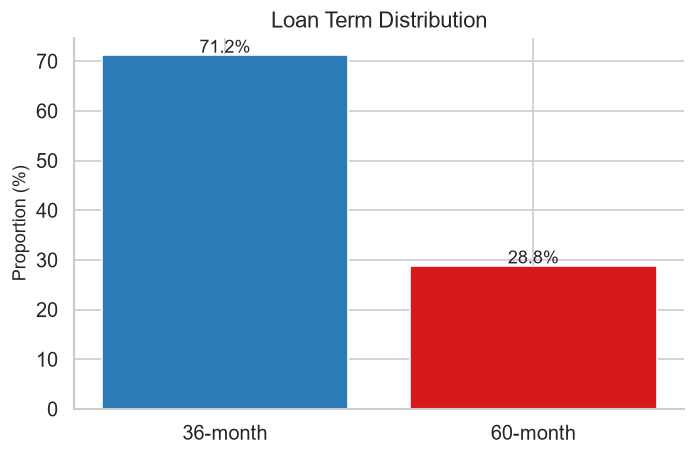

In [6]:
# Term distribution — 36 vs 60 months
term_counts = df['term'].value_counts().sort_index()
term_pcts   = term_counts / term_counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    [f'{t}-month' for t in term_counts.index],
    term_pcts.values,
    color=[PLOT_COLOR, ACCENT_COLOR],
    edgecolor='white',
)
for i, val in enumerate(term_pcts.values):
    ax.text(i, val + 0.5, f'{val:.1f}%', ha='center', fontsize=11)
ax.set_title('Loan Term Distribution')
ax.set_ylabel('Proportion (%)')
plt.tight_layout()
save_figure(fig, '02_term_distribution.png')
plt.show()

## 4. Outlier Analysis

Boxplots highlight extreme values. Annual income and revolving balance are the most skewed.

2026-07-26 00:46:44 | INFO     | src.utils | Figure saved → reports\02_outlier_analysis.png


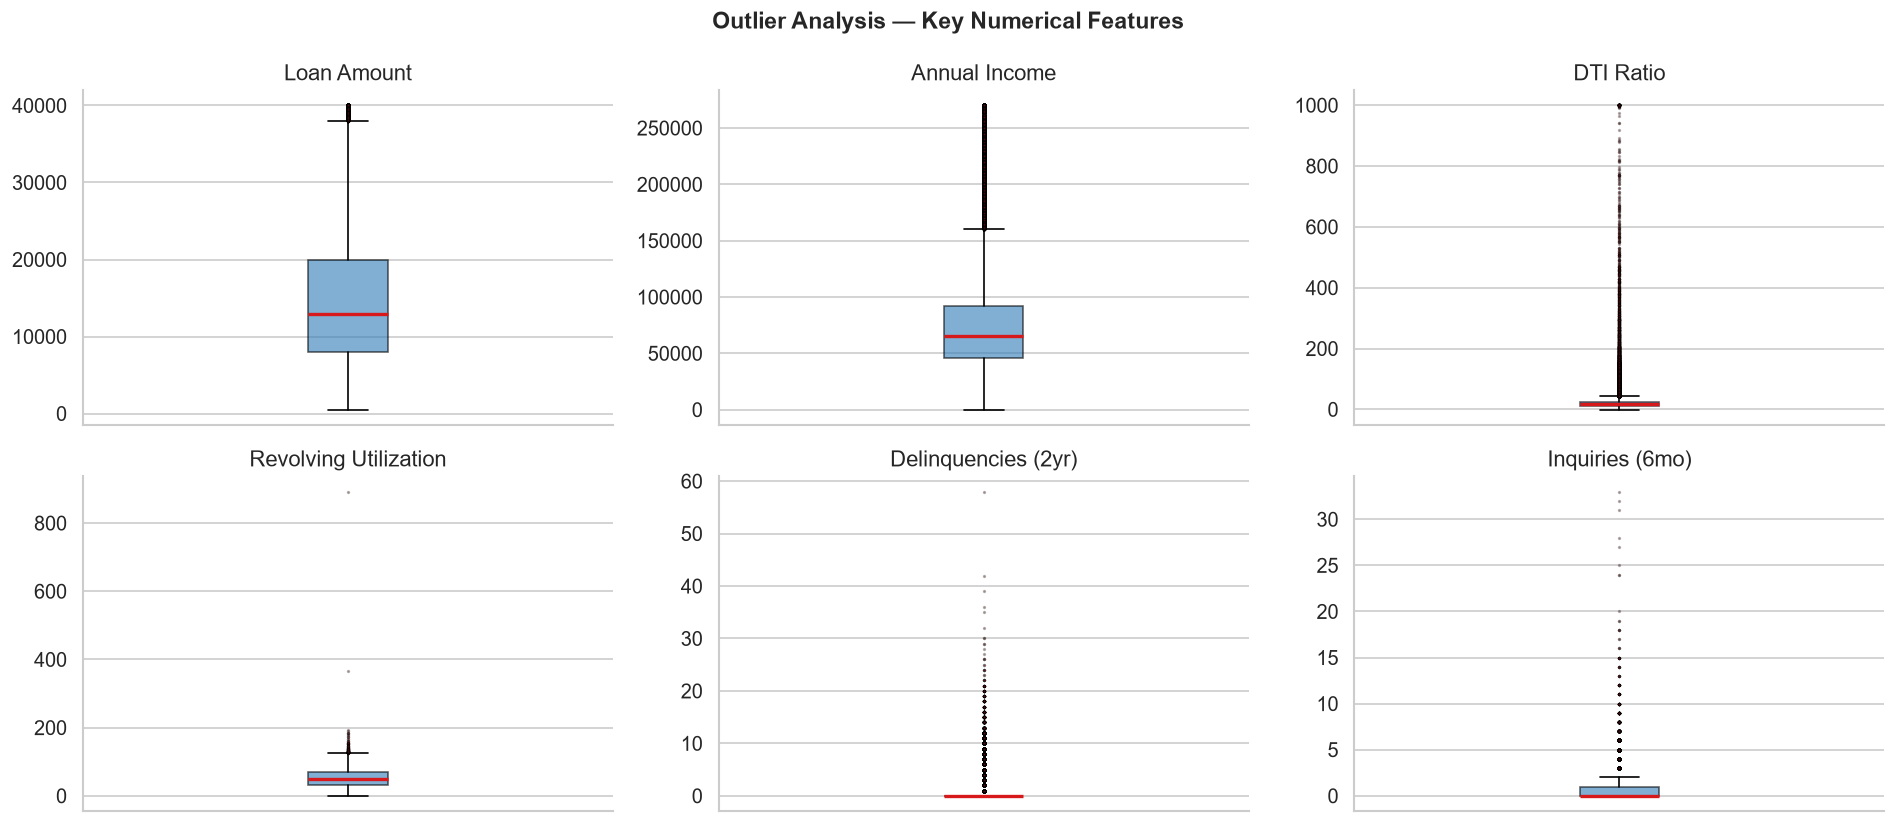

In [7]:
outlier_features = ['loan_amnt', 'annual_inc', 'dti', 'revol_util', 'delinq_2yrs', 'inq_last_6mths']
outlier_titles   = ['Loan Amount', 'Annual Income', 'DTI Ratio', 'Revolving Utilization', 'Delinquencies (2yr)', 'Inquiries (6mo)']

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
axes = axes.flatten()

for i, (feat, title) in enumerate(zip(outlier_features, outlier_titles)):
    col_data = df[feat].dropna()
    # Cap at 99th percentile for annual_inc to make boxplot readable
    if feat == 'annual_inc':
        cap = col_data.quantile(0.99)
        col_data = col_data[col_data <= cap]
    axes[i].boxplot(col_data, vert=True, patch_artist=True,
                    boxprops=dict(facecolor=PLOT_COLOR, alpha=0.6),
                    medianprops=dict(color=ACCENT_COLOR, linewidth=2),
                    flierprops=dict(marker='.', markerfacecolor=ACCENT_COLOR, markersize=2, alpha=0.3))
    axes[i].set_title(title)
    axes[i].set_xticks([])

fig.suptitle('Outlier Analysis — Key Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
save_figure(fig, '02_outlier_analysis.png')
plt.show()

## 5. Correlation Analysis

Examining correlations between numerical features and the `default` target. Positive correlation = associated with higher default.

2026-07-26 00:47:19 | INFO     | src.utils | Figure saved → reports\02_correlation_heatmap.png


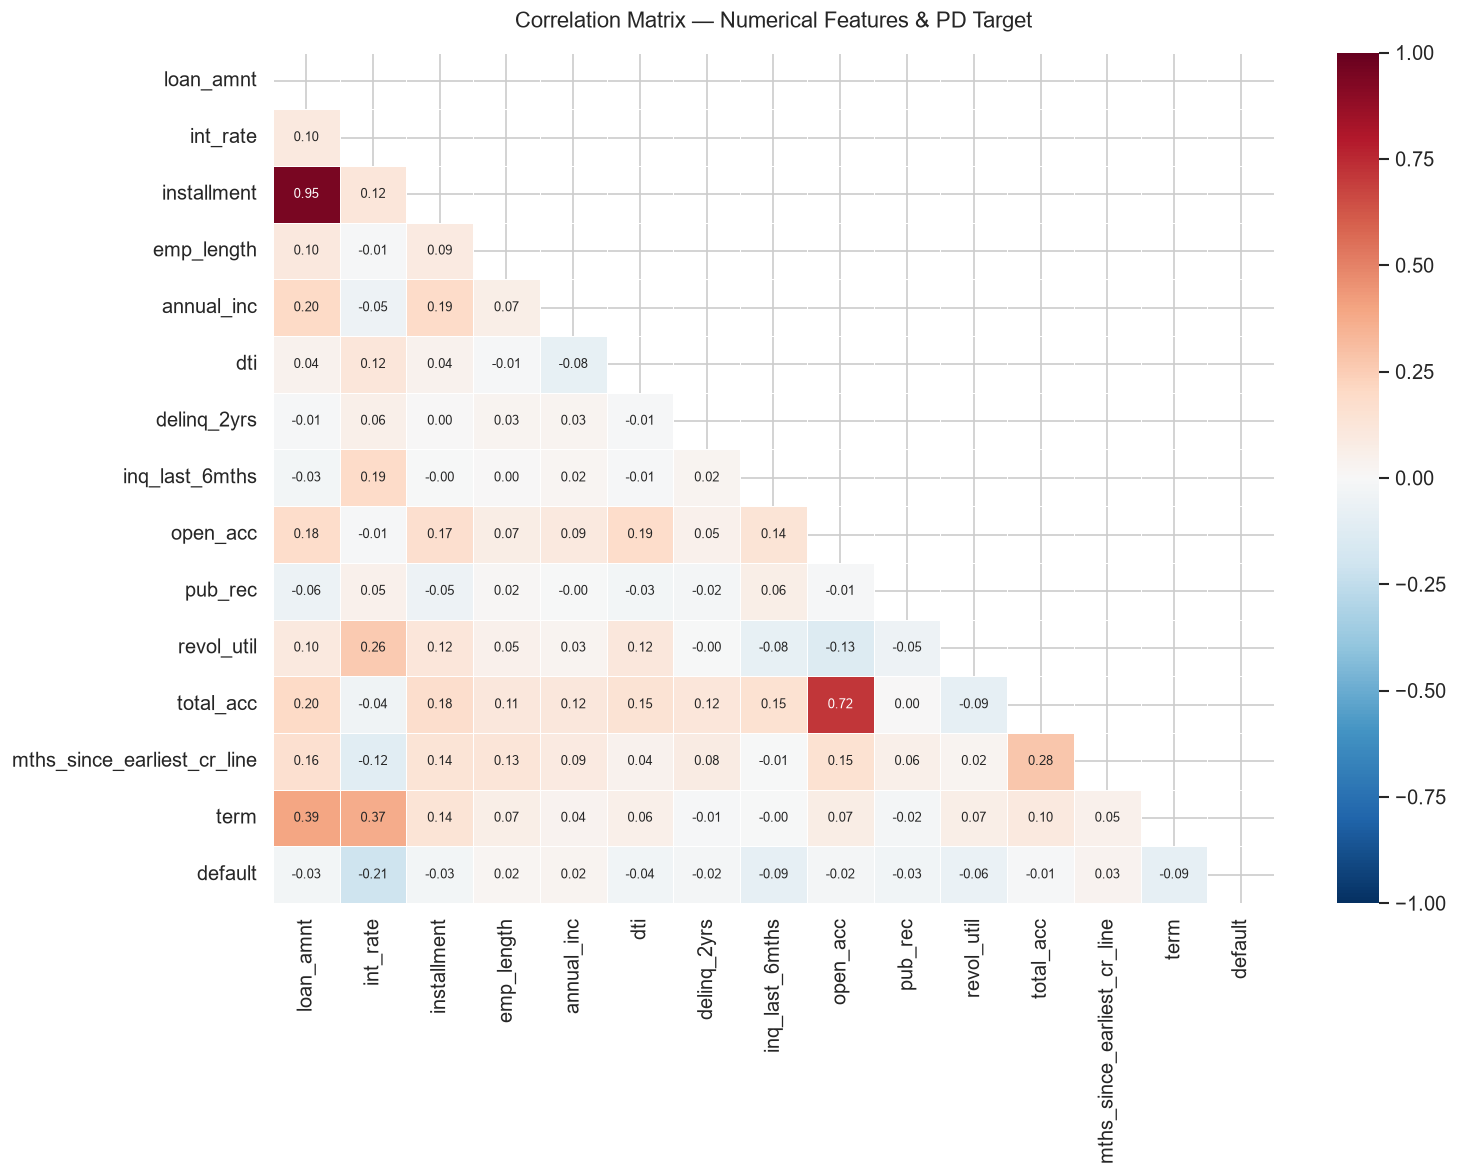

In [8]:
corr_features = [
    'loan_amnt', 'int_rate', 'installment', 'emp_length',
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_util', 'total_acc',
    'mths_since_earliest_cr_line', 'term', 'default',
]
# Keep only columns that exist after cleaning
corr_features = [c for c in corr_features if c in df.columns]

corr_matrix = df[corr_features].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 8},
)
ax.set_title('Correlation Matrix — Numerical Features & PD Target', fontsize=13, pad=15)
plt.tight_layout()
save_figure(fig, '02_correlation_heatmap.png')
plt.show()

2026-07-26 00:48:16 | INFO     | src.utils | Figure saved → reports\02_correlation_with_target.png


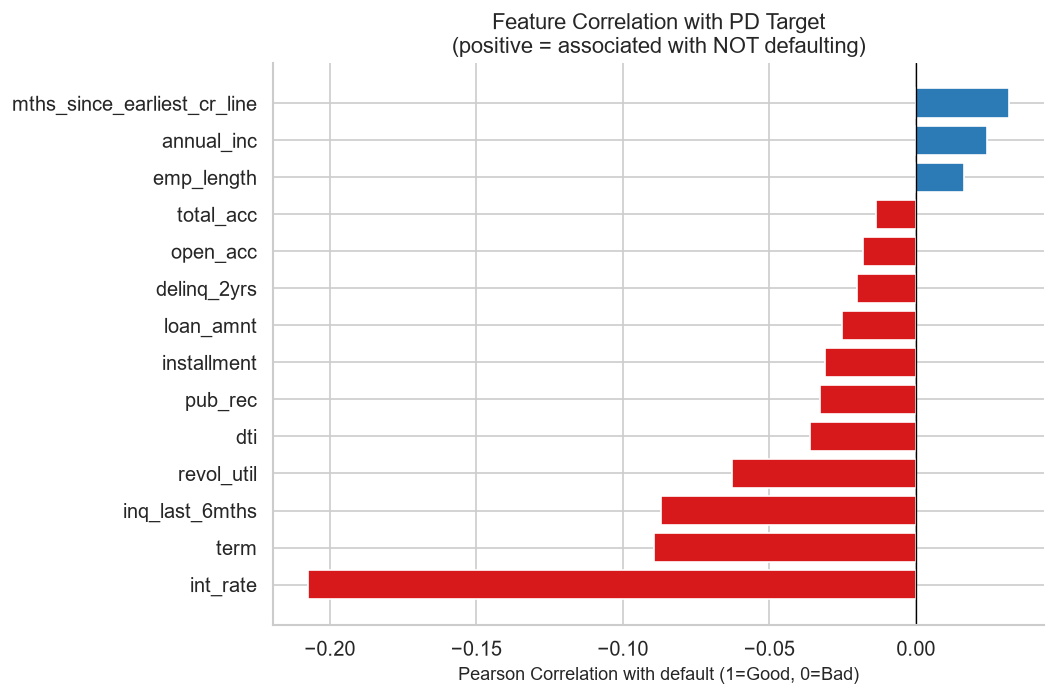

In [ ]:
# Mutual Information — captures non-linear relationships that Pearson misses.
# More appropriate than Pearson for a binary classification target.
# Full IV analysis (requires WoE bins) is performed in the feature engineering notebook.
# Uses a stratified 10% sample to keep computation fast on 2.26M rows.
from sklearn.feature_selection import mutual_info_classif

mi_features = [c for c in [
    'loan_amnt', 'int_rate', 'installment', 'emp_length',
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_util', 'total_acc',
    'mths_since_earliest_cr_line', 'term',
    'fico_range_low', 'fico_range_high',
] if c in df.columns]

# Stratified 10% sample — sample each class separately, then concatenate
full = df[mi_features + ['default']].dropna()
good = full[full['default'] == 1].sample(frac=0.10, random_state=42)
bad  = full[full['default'] == 0].sample(frac=0.10, random_state=42)
mi_data = pd.concat([good, bad]).reset_index(drop=True)
print(f'MI sample: {len(mi_data):,} rows  |  default rate: {1 - mi_data["default"].mean():.2%}')

X_mi = mi_data[mi_features].astype(float)
y_mi = mi_data['default']

mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features='auto', random_state=42)
mi_series = pd.Series(mi_scores, index=mi_features).sort_values(ascending=True)

top_q = mi_series.quantile(0.75)
colors = [ACCENT_COLOR if v >= top_q else PLOT_COLOR for v in mi_series]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mi_series.index, mi_series.values, color=colors)
ax.axvline(top_q, color=ACCENT_COLOR, linestyle='--', linewidth=1.2, label='Top-quartile threshold')
ax.set_xlabel('Mutual Information Score')
ax.set_title(
    'Feature Importance — Mutual Information with PD Target\n'
    '(non-linear relationships; full IV analysis in the feature engineering notebook)'
)
ax.legend()
plt.tight_layout()
save_figure(fig, '02_mutual_information.png')
plt.show()

print('\nMI scores (descending):')
print(mi_series[::-1].to_string())

## 6. Default Rate Analysis by Key Variables

The default rate (proportion of bad loans) is analysed across key categorical and binned numerical features.
These plots directly validate the credit risk methodology and inform feature selection.

2026-07-26 00:48:57 | INFO     | src.utils | Figure saved → reports\02_default_rate_by_grade.png


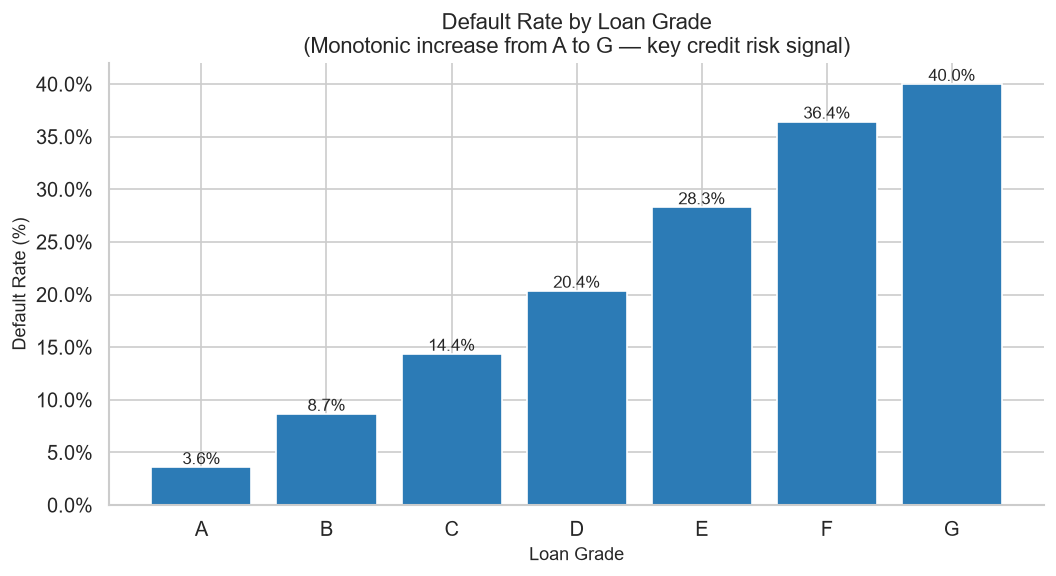

In [10]:
# -- Default rate by grade (expected: monotonic increase A -> G) --
grade_order = sorted(df['grade'].astype(str).unique())
dr_grade = (
    df.groupby(df['grade'].astype(str))['default']
    .apply(lambda x: 1 - x.mean())
    .reindex(grade_order)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(dr_grade.index, dr_grade.values * 100, color=PLOT_COLOR, edgecolor='white')
for bar, val in zip(bars, dr_grade.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val:.1%}', ha='center', fontsize=10)
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Default Rate (%)')
ax.set_title('Default Rate by Loan Grade\n(Monotonic increase from A to G — key credit risk signal)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
save_figure(fig, '02_default_rate_by_grade.png')
plt.show()

2026-07-26 00:49:44 | INFO     | src.utils | Figure saved → reports\02_default_rate_by_intrate.png


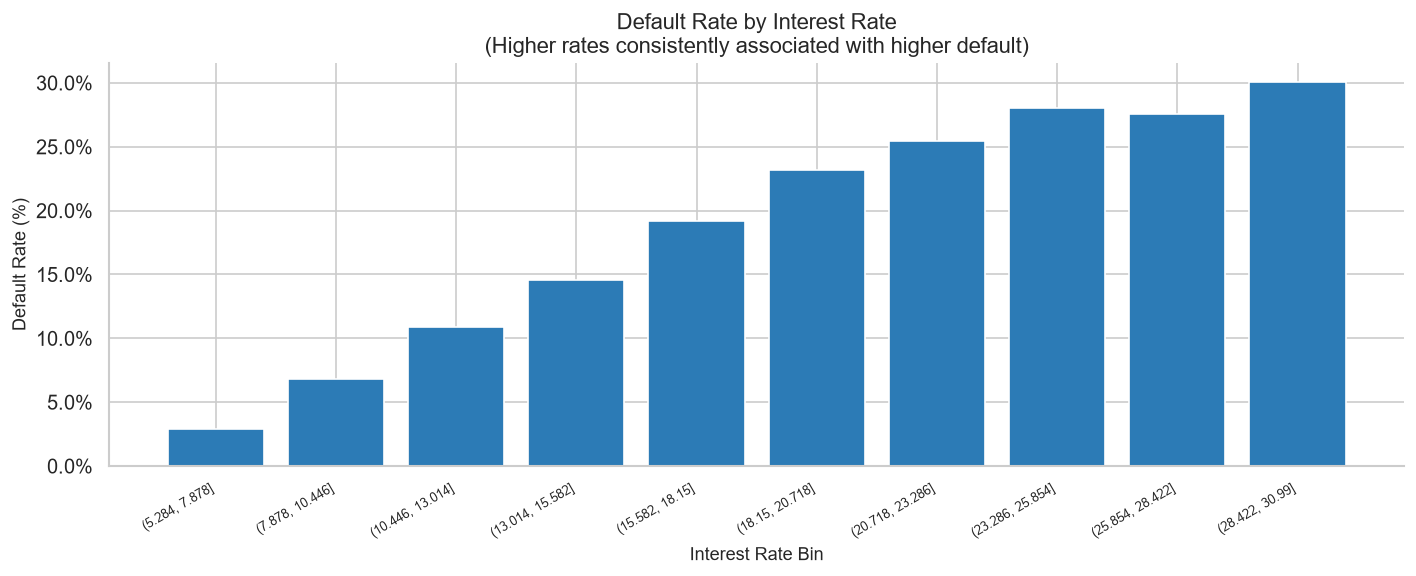

In [11]:
# -- Default rate by interest rate bins --
df['int_rate_bin'] = pd.cut(df['int_rate'], bins=10)
dr_intrate = df.groupby('int_rate_bin', observed=True)['default'].apply(lambda x: 1 - x.mean())

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    range(len(dr_intrate)),
    dr_intrate.values * 100,
    color=PLOT_COLOR,
    edgecolor='white',
)
ax.set_xticks(range(len(dr_intrate)))
ax.set_xticklabels([str(b) for b in dr_intrate.index], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Interest Rate Bin')
ax.set_title('Default Rate by Interest Rate\n(Higher rates consistently associated with higher default)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
save_figure(fig, '02_default_rate_by_intrate.png')
plt.show()

df = df.drop(columns=['int_rate_bin'])

2026-07-26 00:50:29 | INFO     | src.utils | Figure saved → reports\02_default_rate_by_income.png


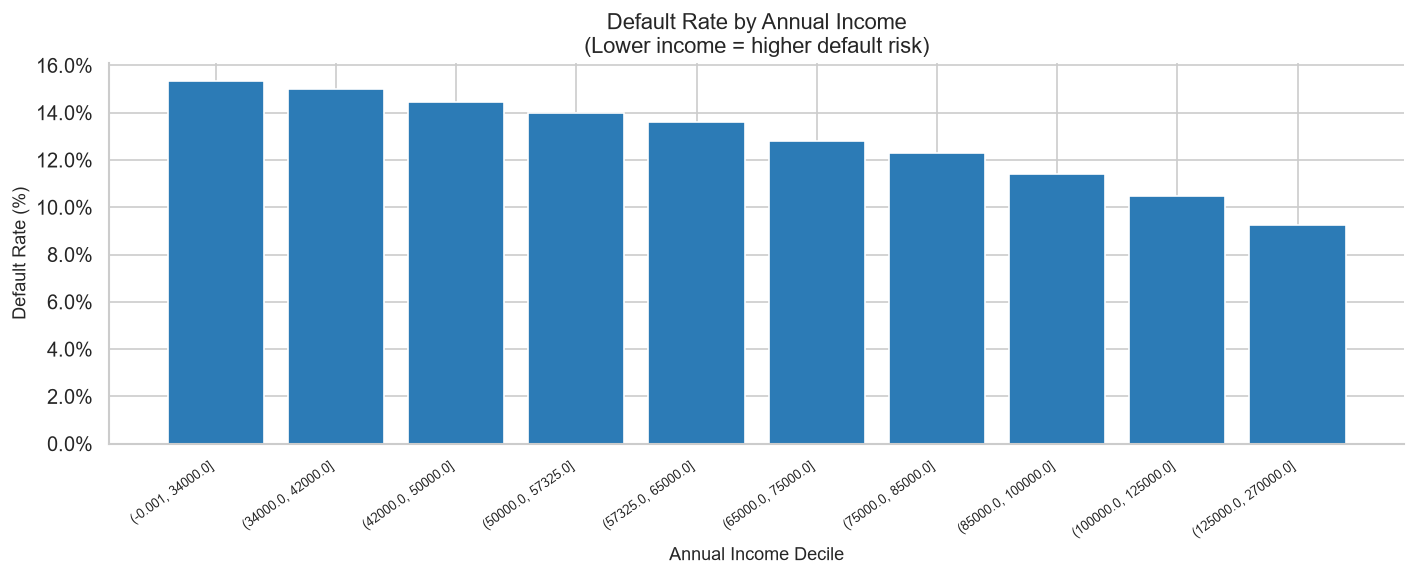

In [12]:
# -- Default rate by annual income bins --
inc_cap = df['annual_inc'].quantile(0.99)
df_inc  = df[df['annual_inc'] <= inc_cap].copy()
df_inc['inc_bin'] = pd.qcut(df_inc['annual_inc'], q=10)
dr_income = df_inc.groupby('inc_bin', observed=True)['default'].apply(lambda x: 1 - x.mean())

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(dr_income)), dr_income.values * 100, color=PLOT_COLOR, edgecolor='white')
ax.set_xticks(range(len(dr_income)))
ax.set_xticklabels([str(b) for b in dr_income.index], rotation=35, ha='right', fontsize=8)
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Annual Income Decile')
ax.set_title('Default Rate by Annual Income\n(Lower income = higher default risk)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
save_figure(fig, '02_default_rate_by_income.png')
plt.show()

2026-07-26 00:51:11 | INFO     | src.utils | Figure saved → reports\02_default_rate_term_homeown.png


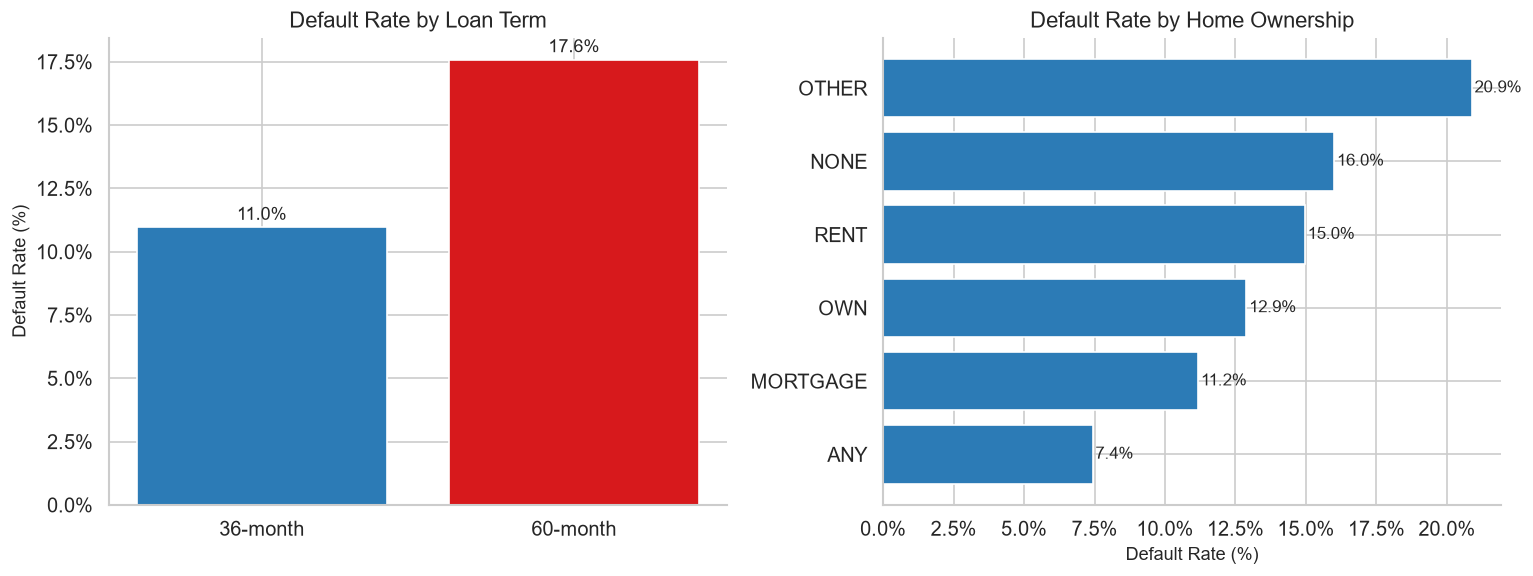

In [13]:
# -- Default rate by term and home ownership --
dr_term   = df.groupby('term')['default'].apply(lambda x: 1 - x.mean())
dr_homeown = df.groupby(df['home_ownership'].astype(str))['default'].apply(lambda x: 1 - x.mean()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Term
axes[0].bar([f'{t}-month' for t in dr_term.index], dr_term.values * 100,
            color=[PLOT_COLOR, ACCENT_COLOR], edgecolor='white')
for i, val in enumerate(dr_term.values):
    axes[0].text(i, val * 100 + 0.3, f'{val:.1%}', ha='center', fontsize=11)
axes[0].set_title('Default Rate by Loan Term')
axes[0].set_ylabel('Default Rate (%)')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())

# Home ownership
axes[1].barh(dr_homeown.index, dr_homeown.values * 100, color=PLOT_COLOR)
for i, val in enumerate(dr_homeown.values):
    axes[1].text(val * 100 + 0.1, i, f'{val:.1%}', va='center', fontsize=10)
axes[1].set_title('Default Rate by Home Ownership')
axes[1].set_xlabel('Default Rate (%)')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
save_figure(fig, '02_default_rate_term_homeown.png')
plt.show()

## 7. Time Trend Analysis

Understanding loan volume and default rate trends over time is essential for:
1. Justifying the **Out-of-Time (OOT) split** boundary year.
2. Detecting any population drift before building the PSI monitoring module.

2026-07-26 00:51:51 | INFO     | src.utils | Figure saved → reports\02_time_trend.png


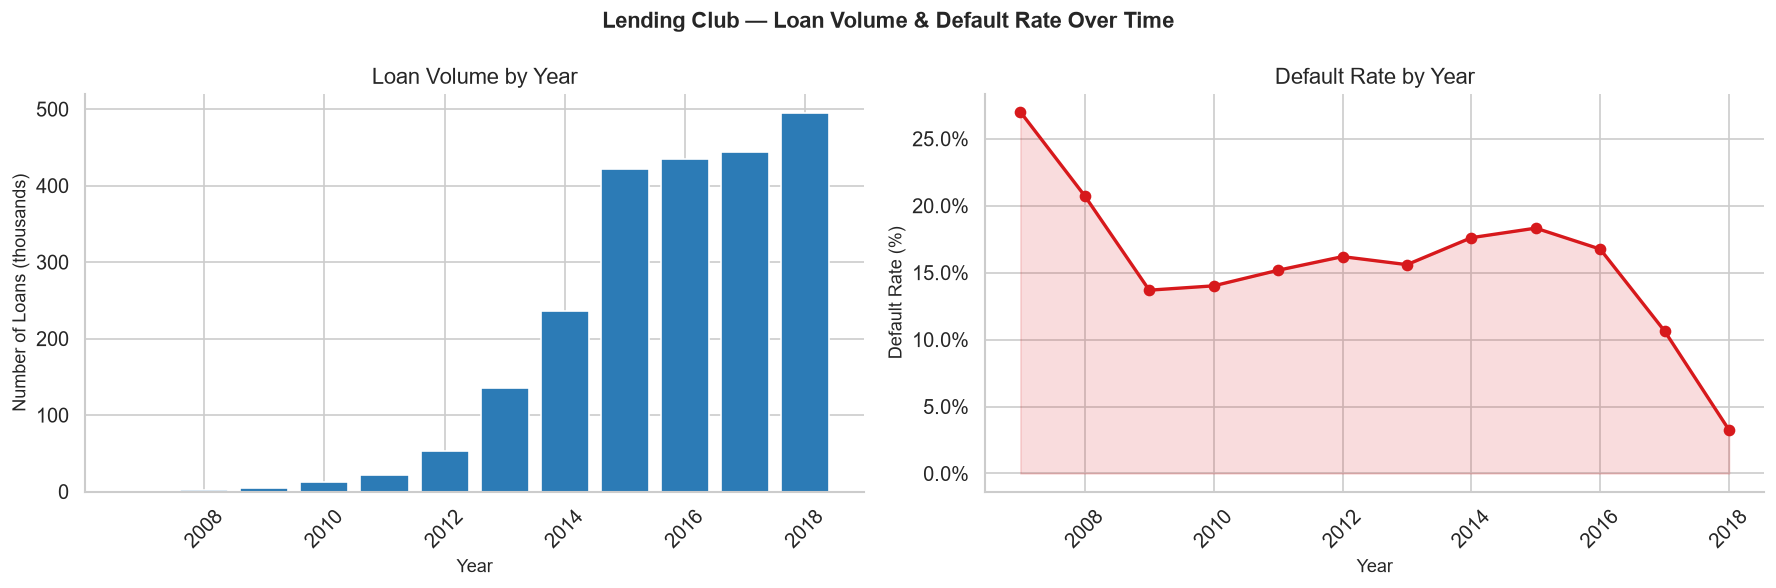

In [14]:
df['issue_year'] = df['issue_d'].dt.year

loan_vol    = df.groupby('issue_year').size()
default_rate_by_year = df.groupby('issue_year')['default'].apply(lambda x: 1 - x.mean())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loan volume
axes[0].bar(loan_vol.index, loan_vol.values / 1000, color=PLOT_COLOR, edgecolor='white')
axes[0].set_title('Loan Volume by Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Loans (thousands)')
axes[0].tick_params(axis='x', rotation=45)

# Default rate over time
axes[1].plot(default_rate_by_year.index, default_rate_by_year.values * 100,
             marker='o', color=ACCENT_COLOR, linewidth=2, markersize=6)
axes[1].fill_between(default_rate_by_year.index, default_rate_by_year.values * 100,
                     alpha=0.15, color=ACCENT_COLOR)
axes[1].set_title('Default Rate by Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Default Rate (%)')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].tick_params(axis='x', rotation=45)

fig.suptitle('Lending Club — Loan Volume & Default Rate Over Time', fontsize=13, fontweight='bold')
plt.tight_layout()
save_figure(fig, '02_time_trend.png')
plt.show()

df = df.drop(columns=['issue_year'])

## 8. Business Insights Summary

### Credit Risk Indicators

| Finding | Business Interpretation |
|---------|-------------------------|
| **Grade → Default Rate** | Perfectly monotonic A (3.6%) → G (40%). Strongest single credit risk signal. |
| **Interest Rate → Default Rate** | Monotonic — higher rates reflect higher perceived risk, confirmed empirically. |
| **Annual Income → Default Rate** | Monotonic decrease — lower income = significantly higher default probability. |
| **60-month term** | 17.6% default vs 11.0% for 36-month — duration adds substantial risk. |
| **Class imbalance** | 12.86% default rate, 6.8:1 ratio — models need `class_weight='balanced'` or threshold tuning. |
| **Mutual Information top features** | `int_rate`, `fico_range_low/high`, `annual_inc`, `dti` — confirmed as the strongest predictors for the PD model. |
| **Extreme outliers** | `dti` max=999, `revol_util` max=892 — these are data errors that are capped before modelling. |

### Out-of-Time (OOT) Split Design

The time trend analysis confirms the following split:

| Split | Date Range | Rationale |
|-------|------------|-----------|
| **Train** | Jan 2007 – Dec 2015 | 9 years of mature loans with known outcomes |
| **Validation / Test** | Jan 2016 – Dec 2016 | One-year holdout for model selection and threshold tuning |
| **OOT** | Jan 2017 – Dec 2018Q4 | True out-of-time evaluation — never seen during training or tuning |

> **Note:** The apparent drop in default rate for 2017–2018 in the time trend plot is **not** because those loans are safer — it is the **performance window effect**: recent loans have not yet had enough time to mature into confirmed defaults. This makes them unsuitable for training and confirms that 2017–2018 should be held as the OOT set.

### Implications for Feature Engineering

1. **WoE/IV analysis** will formally quantify each feature's discriminatory power — confirming or rejecting the MI findings above.
2. **Leakage removal**: Post-outcome columns (`recoveries`, `total_pymnt`, `out_prncp`, etc.) will be dropped from the PD feature set before any fitting.
3. **Outlier capping**: `dti` and `revol_util` will be capped at reasonable percentiles (e.g. 99th).
4. **OOT split** at the boundary **Dec 2015 / Jan 2016** — applied before WoE fitting to prevent leakage.
5. **Missing as category**: `mths_since_last_delinq` and similar columns with informative missingness will be treated as a separate WoE bin.

**Next:** The following notebook performs feature engineering on the cleaned dataset for WoE, IV, dummy creation, OOT split, and scaling.
